# 1. Load Dataset
  - Dataset Link: "https://universe.roboflow.com/roboflow-universe-projects/construction-site-safety/dataset/30#"

In [1]:
!pip install roboflow ultralytics



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 72.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 50.4 MB/s  0:00:00
  Attempting uninstall: typer━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [ultralytics-platform]
    Found existing installation: typer 0.27.2━━━━━━━━━━━━━━━━━ 1/6 [ultralytics-platform]
    Uninstalling typer-0.27.2:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [ultralytics-platform]
      Successfully uninstalled typer-0.27.2━━━━━━━━━━━━━━━━━━━ 1/6 [ultralytics-platform]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [ultralytics] [ultralytics]form]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="wNPGxnIaS0ZRR6jYHRfn")
project = rf.workspace("roboflow-universe-projects").project("construction-site-safety")
version = project.version(30)
dataset = version.download("yolov11")
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Construction-Site-Safety-30 in yolov11:: 100%|██████████| 1446/1446 [00:00<00:00, 7405.13it/s]


In [47]:
import yaml
from pathlib import Path

dataset_path = Path(dataset.location)

with open(dataset_path / "data.yaml", "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

print("Number of classes:", data["nc"])

print("\nOriginal Classes:")
for class_id, class_name in enumerate(
    data["names"].values()
    if isinstance(data["names"], dict)
    else data["names"]
):
    print(f"{class_id}: {class_name}")

Number of classes: 25

Original Classes:
0: Excavator
1: Gloves
2: Hardhat
3: Ladder
4: Mask
5: NO-Hardhat
6: NO-Mask
7: NO-Safety Vest
8: Person
9: SUV
10: Safety Cone
11: Safety Vest
12: bus
13: dump truck
14: fire hydrant
15: machinery
16: mini-van
17: sedan
18: semi
19: trailer
20: truck
21: truck and trailer
22: van
23: vehicle
24: wheel loader


In [48]:

from pathlib import Path
from collections import Counter
import shutil
import yaml

# =====================================
# 1. CONFIGURATION
# =====================================

SOURCE_DIR = Path(dataset.location).resolve()
OUTPUT_DIR = SOURCE_DIR.parent / "PPE_Filtered"

TARGET_CLASSES = ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Safety Vest']

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# =====================================
# 2. READ ORIGINAL YAML
# =====================================

with open(SOURCE_DIR / "data.yaml", "r", encoding="utf-8") as f:
    original_yaml = yaml.safe_load(f)

original_names = original_yaml["names"]

if isinstance(original_names, dict):
    original_classes = {
        int(k): v for k, v in original_names.items()
    }
else:
    original_classes = dict(enumerate(original_names))

print("Original Classes:")
for class_id, name in original_classes.items():
    print(f"{class_id}: {name}")

# =====================================
# 3. CREATE CLASS MAPPING
# =====================================

name_to_id = {
    name: class_id
    for class_id, name in original_classes.items()
}

missing = [
    name for name in TARGET_CLASSES
    if name not in name_to_id
]

if missing:
    raise ValueError(
        f"Classes not found in original dataset: {missing}"
    )

class_mapping = {
    name_to_id[name]: new_id
    for new_id, name in enumerate(TARGET_CLASSES)
}

print("\nClass Mapping:")
for old_id, new_id in class_mapping.items():
    print(
        f"{old_id} ({original_classes[old_id]}) "
        f"-> {new_id} ({TARGET_CLASSES[new_id]})"
    )

# =====================================
# 4. FILTER DATASET
# =====================================

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists: {OUTPUT_DIR}"
    )

OUTPUT_DIR.mkdir(parents=True)

distribution = Counter()
split_statistics = {}

for split in ["train", "valid", "val", "test"]:

    source_images = SOURCE_DIR / split / "images"
    source_labels = SOURCE_DIR / split / "labels"

    if not source_images.exists():
        continue

    if not source_labels.exists():
        raise FileNotFoundError(
            f"Missing labels directory: {source_labels}"
        )

    output_split = "val" if split == "valid" else split

    output_images = OUTPUT_DIR / output_split / "images"
    output_labels = OUTPUT_DIR / output_split / "labels"

    output_images.mkdir(parents=True, exist_ok=True)
    output_labels.mkdir(parents=True, exist_ok=True)

    image_count = 0
    removed_images = 0
    box_count = 0

    for image_path in sorted(source_images.iterdir()):

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        label_path = source_labels / f"{image_path.stem}.txt"

        filtered_labels = []

        if label_path.exists():

            with open(label_path, "r", encoding="utf-8") as f:
                lines = f.readlines()

            for line_number, line in enumerate(lines, 1):

                parts = line.strip().split()

                if not parts:
                    continue

                if len(parts) != 5:
                    raise ValueError(
                        f"Invalid YOLO annotation: "
                        f"{label_path}, line {line_number}"
                    )

                old_id = int(parts[0])

                if old_id not in class_mapping:
                    continue

                coords = [float(x) for x in parts[1:]]

                x, y, w, h = coords

                if not (
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1 and
                    x - w / 2 >= -1e-6 and
                    x + w / 2 <= 1 + 1e-6 and
                    y - h / 2 >= -1e-6 and
                    y + h / 2 <= 1 + 1e-6
                ):
                    raise ValueError(
                        f"Invalid bounding box: {label_path}"
                    )

                new_id = class_mapping[old_id]

                filtered_labels.append(
                    f"{new_id} " +
                    " ".join(parts[1:])
                )

                distribution[TARGET_CLASSES[new_id]] += 1
                box_count += 1

        # Keep only images containing selected classes
        if not filtered_labels:
            removed_images += 1
            continue

        shutil.copy2(
            image_path,
            output_images / image_path.name
        )

        with open(
            output_labels / f"{image_path.stem}.txt",
            "w",
            encoding="utf-8"
        ) as f:
            f.write("\n".join(filtered_labels) + "\n")

        image_count += 1

    split_statistics[output_split] = {
        "images": image_count,
        "boxes": box_count,
        "removed_images": removed_images
    }

# =====================================
# 5. UPDATE DATA.YAML
# =====================================

if "train" not in split_statistics:
    raise ValueError("Training split not found.")

if "val" not in split_statistics:
    raise ValueError("Validation split not found.")

new_yaml = {
    "path": str(OUTPUT_DIR.resolve()),
    "train": "train/images",
    "val": "val/images",
    "nc": len(TARGET_CLASSES),
    "names": TARGET_CLASSES
}

if "test" in split_statistics:
    new_yaml["test"] = "test/images"

with open(
    OUTPUT_DIR / "data.yaml",
    "w",
    encoding="utf-8"
) as f:
    yaml.safe_dump(new_yaml, f, sort_keys=False)

# =====================================
# 6. VALIDATE OUTPUT DATASET
# =====================================

print("\n========== VALIDATION ==========")

for split, stats in split_statistics.items():

    images_dir = OUTPUT_DIR / split / "images"
    labels_dir = OUTPUT_DIR / split / "labels"

    image_files = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in image_files:

        label_path = labels_dir / f"{image_path.stem}.txt"

        assert label_path.exists(), (
            f"Missing label: {label_path}"
        )

        for line in label_path.read_text().splitlines():

            parts = line.split()

            assert len(parts) == 5

            class_id = int(parts[0])

            assert 0 <= class_id < len(TARGET_CLASSES)

            x, y, w, h = map(float, parts[1:])

            assert 0 <= x <= 1
            assert 0 <= y <= 1
            assert 0 < w <= 1
            assert 0 < h <= 1

    print(
        f"{split}: "
        f"{len(image_files)} images | "
        f"{stats['boxes']} boxes | "
        f"{stats['removed_images']} removed images"
    )

print("\n========== CLASS DISTRIBUTION ==========")

for class_id, name in enumerate(TARGET_CLASSES):
    print(
        f"{class_id}: {name:<18} "
        f"{distribution[name]} boxes"
    )

print("\nFiltering completed successfully!")
print("Output:", OUTPUT_DIR)
print("YAML:", OUTPUT_DIR / "data.yaml")


Original Classes:
0: Excavator
1: Gloves
2: Hardhat
3: Ladder
4: Mask
5: NO-Hardhat
6: NO-Mask
7: NO-Safety Vest
8: Person
9: SUV
10: Safety Cone
11: Safety Vest
12: bus
13: dump truck
14: fire hydrant
15: machinery
16: mini-van
17: sedan
18: semi
19: trailer
20: truck
21: truck and trailer
22: van
23: vehicle
24: wheel loader

Class Mapping:
2 (Hardhat) -> 0 (Hardhat)
4 (Mask) -> 1 (Mask)
5 (NO-Hardhat) -> 2 (NO-Hardhat)
6 (NO-Mask) -> 3 (NO-Mask)
7 (NO-Safety Vest) -> 4 (NO-Safety Vest)
11 (Safety Vest) -> 5 (Safety Vest)

========== VALIDATION ==========
train: 344 images | 1876 boxes | 177 removed images
val: 81 images | 390 boxes | 33 removed images
test: 55 images | 409 boxes | 27 removed images

========== CLASS DISTRIBUTION ==========
0: Hardhat            574 boxes
1: Mask               202 boxes
2: NO-Hardhat         402 boxes
3: NO-Mask            491 boxes
4: NO-Safety Vest     582 boxes
5: Safety Vest        424 boxes

Filtering completed successfully!
Output: /kaggle/work

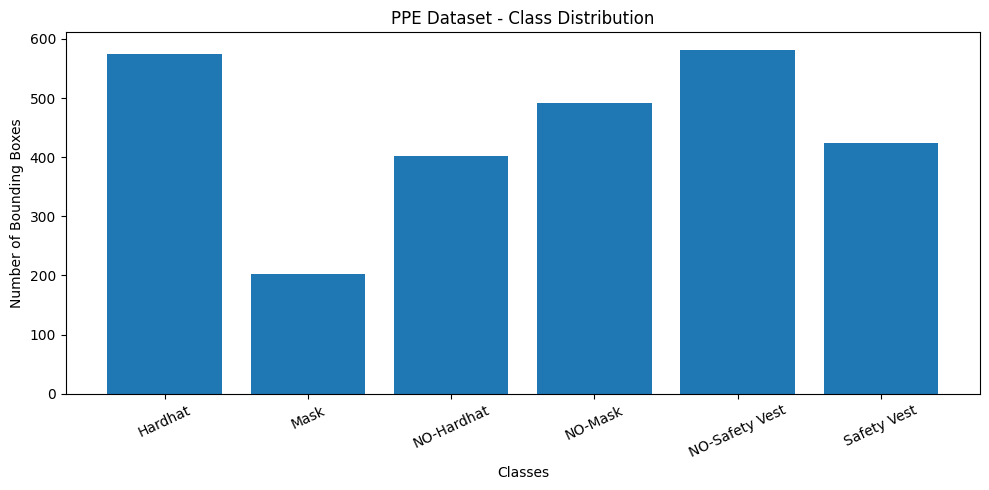

In [49]:
import matplotlib.pyplot as plt

classes = TARGET_CLASSES
counts = [distribution[name] for name in classes]

plt.figure(figsize=(10, 5))
plt.bar(classes, counts)

plt.title("PPE Dataset - Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Bounding Boxes")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 2. Train YOLOv11 Model

In [50]:
import ultralytics
from ultralytics import YOLO
ultralytics.checks()

Ultralytics 8.4.199 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7190.1/8156.9 GB disk)


In [51]:
model= YOLO('yolo11s.pt')

In [52]:

# Train Model with Optimized Strong Augmentations

print('Training Started.. 🔥')

results = model.train(
    data="/kaggle/working/PPE_Filtered/data.yaml",
    epochs=120,
    imgsz=640,
    batch=16,
    device=0,
    patience=25,

    # --- Optimized Strong Augmentation Settings ---

    mosaic=0.8,          # Combines 4 images; improves object-scale and context diversity
    close_mosaic=15,     # Disables mosaic for the final 15 epochs
    mixup=0.05,          # Mild image blending; avoids obscuring small PPE objects
    copy_paste=0.0,      # Disabled: standard copy_paste is for segmentation, not regular detection

    degrees=7.0,        # Rotates images by up to ±7 degrees
    translate=0.10,     # Shifts images by up to 10%
    scale=0.40,         # Random scaling to simulate different object distances
    shear=1.0,          # Mild shear transformation
    perspective=0.0002, # Small perspective changes

    fliplr=0.5,         # Horizontal flip probability of 50%
    flipud=0.0,         # No vertical flipping

    hsv_h=0.01,         # Mild hue variation
    hsv_s=0.40,         # Moderate saturation variation
    hsv_v=0.30,         # Brightness variation for different lighting conditions

    # --- Optimization Settings ---

    optimizer="AdamW",  # Explicit optimizer for reproducible experiments
    lr0=0.001,          # Initial learning rate
    lrf=0.01,          # Final learning rate factor
    cos_lr=True,       # Cosine learning rate scheduling
    weight_decay=0.0005,
    warmup_epochs=3.0,

    # --- Training Settings ---

    amp=True,
    plots=True,
    seed=42,

    project="/kaggle/working/runs/PPE-Detection",
    name="optimized_augmentation_v1",
)

print('Train Finished Successfully ✅✅')


Training Started.. 🔥
Ultralytics 8.4.199 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/PPE_Filtered/data.yaml, degrees=7.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=120, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.8, multi_scale=0.0, name=optimized_augmentation_v1, n

In [55]:
from ultralytics import YOLO

model = YOLO(
    "/kaggle/working/runs/PPE-Detection/optimized_augmentation_v1/weights/best.pt"
)

metrics = model.val(
    data="/kaggle/working/PPE_Filtered/data.yaml",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

for i, name in model.names.items():
    p, r, ap50, ap = metrics.box.class_result(i)
    print(
        f"{name:<18} | "
        f"P={p:.3f} | R={r:.3f} | "
        f"mAP50={ap50:.3f} | mAP50-95={ap:.3f}"
    )

Ultralytics 8.4.199 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1089.5±364.5 MB/s, size: 50.1 KB)
val: Scanning /kaggle/working/PPE_Filtered/val/labels.cache... 81 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 81/81 34.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.1it/s 1.9s0.3s
                   all         81        390      0.809      0.595      0.643      0.396
               Hardhat         42         79      0.911       0.62      0.701       0.51
                  Mask         19         21      0.867       0.81      0.801        0.6
            NO-Hardhat         37         69      0.769      0.481      0.525      0.304
               NO-Mask         44         74      0.633      0.459       0.46      0.148
        NO-Safety Vest         56  